## Chest X-Ray Classification with Vision Transformer

This notebook demonstrates a comprehensive approach to classifying chest X-ray images using a Vision Transformer (ViT) model. It covers data loading, preprocessing, model definition, training, evaluation, and prediction.

In [2]:
# Install torchinfo for model summary
!pip install torchinfo

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=90c8a398df99fae67c1a525774a584826159f44a0a28c30be56c6a36d028478c
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam


## 1. Setup and Imports

This section handles the installation of necessary libraries and imports all required modules for the project. Essential libraries for data manipulation, visualization and deep learning are loaded here, ensuring the environment is ready for subsequent steps.

In [3]:
# Standard library imports for operating system interaction, zip file handling, and random operations
import os
import zipfile
import random
import io

# Data handling and numerical operations using pandas and numpy
import numpy as np
import pandas as pd
from PIL import Image

# Visualization libraries for plotting graphs and images
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning utilities from scikit-learn for data splitting and metric computation
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

# Deep Learning framework - PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.cuda.amp import GradScaler, autocast

# Pre-trained models from torchvision for transfer learning
from torchvision import models

# Model summary
from torchinfo import summary

## 2. Environment Check

This section verifies the PyTorch version and checks for GPU availability, ensuring the computing environment is correctly set up for efficient deep learning tasks.

In [4]:
# Print the installed PyTorch version
print("PyTorch Version:", torch.__version__)
# Check and print if a CUDA-enabled GPU is available for use
print("GPU Available:", torch.cuda.is_available())

PyTorch Version: 2.11.0+cu128
GPU Available: True


In [5]:
# Set the device for computations: 'cuda' if GPU is available, otherwise 'cpu'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 3. Kaggle Data Download and Extraction

This section handles the download of the Chest X-Ray dataset from Kaggle. It specifically performs a selective extraction of the `Data_Entry_2017.csv` file, which is crucial as it contains all the metadata and labels required for image classification.

In [6]:
# Import the userdata module from google.colab to access Kaggle API credentials
from google.colab import userdata

# Set Kaggle API key and username as environment variables for authentication
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')

### 3.1 Download Dataset

This subsection downloads the `data.zip` file, which contains the chest X-ray images, from Kaggle to a specified local directory.

In [7]:
import kaggle

# Define the path where Kaggle data will be downloaded and extracted
download_path = '/content/kaggle_data/'
# Create the directory if it does not exist
os.makedirs(download_path, exist_ok=True)

print("Downloading dataset files from Kaggle...")
# Download the 'data' dataset from NIH Chest X-rays. 'unzip=False' means it will download the zip file without extracting its contents immediately.
kaggle.api.dataset_download_files("nih-chest-xrays/data", path=download_path, unzip=False)

Dataset URL: https://www.kaggle.com/datasets/nih-chest-xrays/data


In [8]:
# Construct the full path to the downloaded zip file for future reference
zip_path = os.path.join(download_path, 'data.zip')

### 3.2 List Contents of Zip File

This section inspects the contents of the downloaded `data.zip` file to understand its internal structure and identify where the relevant image directories and metadata files are located.

In [9]:
print('Listing contents of data.zip:')

# Define prefixes for directories that are expected to contain image files
image_directory_prefixes = [f'images_{i:03d}/images/' for i in range(1, 13)]

# Open the main zip file for reading its contents
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    directories = set()
    non_image_files = []

    # Iterate through all members (files and directories) within the zip archive
    for member in zip_ref.namelist():
        if member.endswith('/'):
            # If a member ends with '/', it's a directory
            directories.add(member)
        elif '/' in member:
            # If a member contains '/', it's a file within a directory structure
            dir_part = member[:member.rfind('/') + 1]
            directories.add(dir_part)

            # Check if the file is NOT in one of the predefined image directories
            if not any(member.startswith(prefix) for prefix in image_directory_prefixes):
                non_image_files.append(member)
        else:
            # If no '/', it's a file in the root of the zip archive
            non_image_files.append(member)

    print("\nFolders in data.zip:")
    for d in sorted(list(directories)):
        print(d)

    print("\nNon-image files in data.zip:")
    for f in sorted(non_image_files):
        print(f)

Listing contents of data.zip:

Folders in data.zip:
images_001/images/
images_002/images/
images_003/images/
images_004/images/
images_005/images/
images_006/images/
images_007/images/
images_008/images/
images_009/images/
images_010/images/
images_011/images/
images_012/images/

Non-image files in data.zip:
ARXIV_V5_CHESTXRAY.pdf
BBox_List_2017.csv
Data_Entry_2017.csv
FAQ_CHESTXRAY.pdf
LOG_CHESTXRAY.pdf
README_CHESTXRAY.pdf
test_list.txt
train_val_list.txt


### 3.3 Extract Metadata CSV

This subsection extracts only the `Data_Entry_2017.csv` file from the downloaded zip archive. This CSV file is critical as it contains all patient information and disease labels necessary for setting up the dataset.

In [10]:
# Define the specific CSV file to extract from the zip archive
specific_files_to_extract_names = {'Data_Entry_2017.csv'}

print(f"Starting selective extraction from {zip_path} to {download_path}")
extracted_members = []
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    all_zip_members = zip_ref.namelist()

    # Identify and collect only the specified files for extraction
    for member in all_zip_members:
        if member in specific_files_to_extract_names:
            extracted_members.append(member)

    # Extract only the identified specific files to the download path
    zip_ref.extractall(path=download_path, members=extracted_members)

print("Finished selective extraction of 'Data_Entry_2017.csv'.")

Starting selective extraction from /content/kaggle_data/data.zip to /content/kaggle_data/
Finished selective extraction of 'Data_Entry_2017.csv'.


## 4. Initial Data Loading and Exploration

This section focuses on loading the extracted CSV into a pandas DataFrame. It then performs initial exploratory data analysis to understand the dataset's structure, patient demographics, and the distribution of various disease labels.

In [11]:
# Construct the full path to the extracted CSV file
csv_path = os.path.join(download_path, 'Data_Entry_2017.csv')
# Load the CSV file into a pandas DataFrame
df = pd.read_csv(csv_path)
# Display the first few rows of the DataFrame for initial inspection
display(df.head())

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


### 4.1 DataFrame Information

This subsection displays a concise summary of the DataFrame, providing insights into its data types, the count of non-null values for each column, and overall memory usage. This helps in quickly assessing data completeness and structure.

In [12]:
# Display a concise summary of the DataFrame, including data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112120 entries, 0 to 112119
Data columns (total 12 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Image Index                  112120 non-null  object 
 1   Finding Labels               112120 non-null  object 
 2   Follow-up #                  112120 non-null  int64  
 3   Patient ID                   112120 non-null  int64  
 4   Patient Age                  112120 non-null  int64  
 5   Patient Gender               112120 non-null  object 
 6   View Position                112120 non-null  object 
 7   OriginalImage[Width          112120 non-null  int64  
 8   Height]                      112120 non-null  int64  
 9   OriginalImagePixelSpacing[x  112120 non-null  float64
 10  y]                           112120 non-null  float64
 11  Unnamed: 11                  0 non-null       float64
dtypes: float64(3), int64(5), object(4)
memory usage: 10.3+ MB


### 4.2 Patient ID Analysis

This subsection analyzes the number and percentage of unique patient IDs within the dataset. Understanding patient uniqueness is important for tasks like data splitting to avoid leakage between training and validation sets.

In [13]:
# Calculate the number of unique patient IDs in the DataFrame
unique_patients = df['Patient ID'].nunique()
print(f"Number of unique patients: {unique_patients}")

# Calculate the percentage of unique patients relative to the total number of entries in the DataFrame
unique_percentage = (unique_patients / len(df)) * 100
print(f"Percentage of unique patients: {unique_percentage:.2f}%")

Number of unique patients: 30805
Percentage of unique patients: 27.48%


### 4.3 Disease Appearance Distribution

This subsection calculates and displays the distribution of various disease appearances across the dataset. It provides a frequency count and percentage for each identified disease, offering insight into the class balance and prevalence of different conditions.

In [14]:
# Initialize a list to store all individual disease appearances extracted from 'Finding Labels'
all_disease_appearances = []

# Iterate through the 'Finding Labels' column. Each entry might contain multiple labels separated by '|'.
for labels_str in df['Finding Labels']:
    # Split the string of labels into individual labels and extend the list
    for label in labels_str.split('|'):
        all_disease_appearances.append(label)

# Count the occurrences of each unique disease label using pandas Series value_counts()
disease_appearance_counts = pd.Series(all_disease_appearances).value_counts()

# Calculate the total number of disease appearances (sum of all counts)
total_appearances = disease_appearance_counts.sum()

# Calculate the percentage of each disease appearance relative to the total, rounded to two decimal places
disease_appearance_percentages = (disease_appearance_counts / total_appearances) * 100

# Create a summary DataFrame for disease appearance counts and percentages
disease_appearance_summary = pd.DataFrame({
    'Appearance Count': disease_appearance_counts,
    'Percentage of Total Appearances': disease_appearance_percentages.round(2)
})

print("Distribution of Disease Appearances in the Dataset:")
# Display the summary DataFrame
display(disease_appearance_summary)

Distribution of Disease Appearances in the Dataset:


,Appearance Count,Percentage of Total Appearances
No Finding,60361,42.65
Infiltration,19894,14.06
Effusion,13317,9.41
Atelectasis,11559,8.17
Nodule,6331,4.47
Mass,5782,4.09
Pneumothorax,5302,3.75
Consolidation,4667,3.30
Pleural_Thickening,3385,2.39
Cardiomegaly,2776,1.96


### 4.4 Visualize Disease Distribution

This subsection generates a bar plot to visually represent the distribution of disease appearances. The plot includes percentage labels on top of each bar, making it easy to quickly grasp the prevalence of different diseases in the dataset.

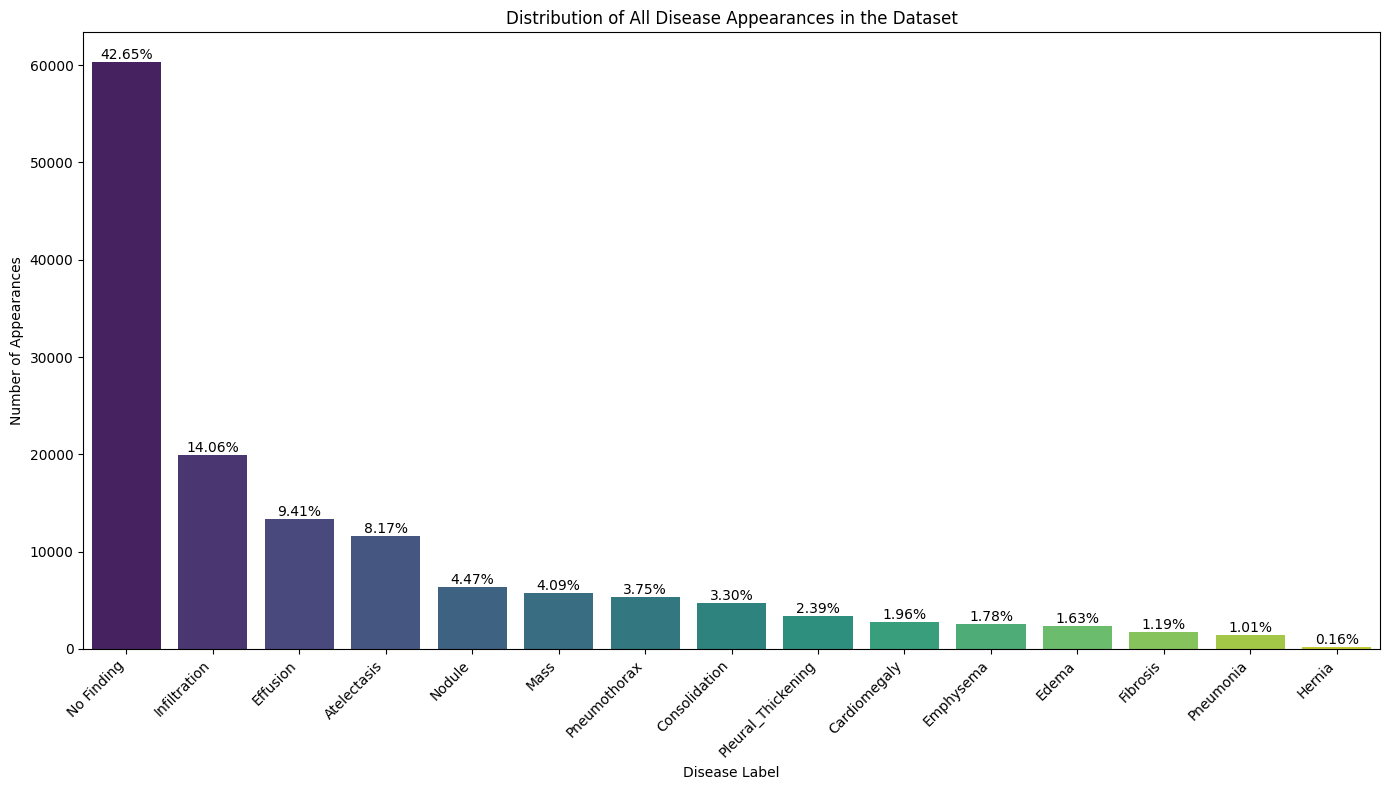

In [15]:
# Create a bar plot to visualize the distribution of disease appearances
plt.figure(figsize=(14, 8))
sns.barplot(x=disease_appearance_summary.index, y=disease_appearance_summary['Appearance Count'], palette='viridis', hue=disease_appearance_summary.index, legend=False)

# Add percentage labels on top of each bar for better readability
for index, row in disease_appearance_summary.iterrows():
    plt.text(index, row['Appearance Count'], f'{row['Percentage of Total Appearances']:.2f}%',
             color='black', ha="center", va='bottom')

plt.title('Distribution of All Disease Appearances in the Dataset')
plt.xlabel('Disease Label')
plt.ylabel('Number of Appearances')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels to prevent overlap
plt.tight_layout() # Adjust layout to ensure everything fits
plt.show()

### 4.5 Average Age per Disease

This subsection calculates and visualizes the average patient age for each disease label. This analysis helps in understanding potential age-related patterns or predispositions for certain conditions within the dataset.

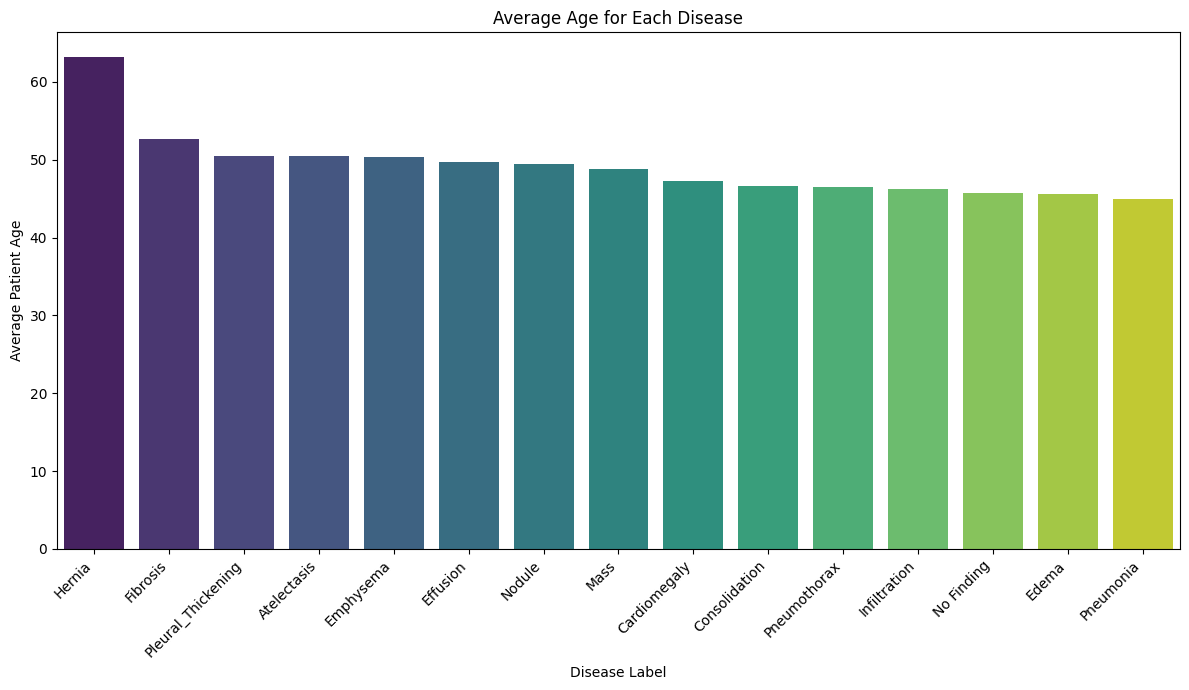

In [16]:
# Create a copy of the DataFrame for disease analysis to avoid modifying the original 'df'
df_disease_analysis = df.copy()

# Split 'Finding Labels' into individual disease entries and then expand the DataFrame rows based on these lists
df_disease_analysis['Finding Labels'] = df_disease_analysis['Finding Labels'].str.split('|')
df_disease_analysis_exploded = df_disease_analysis.explode('Finding Labels')

# Calculate the average age for each unique disease label and sort the results in descending order
avg_age_per_disease = df_disease_analysis_exploded.groupby('Finding Labels')['Patient Age'].mean().sort_values(ascending=False)

# Create a bar plot to visualize the average age for each disease
plt.figure(figsize=(12, 7))
sns.barplot(x=avg_age_per_disease.index, y=avg_age_per_disease.values, palette='viridis', hue=avg_age_per_disease.index, legend=False)
plt.title('Average Age for Each Disease')
plt.xlabel('Disease Label')
plt.ylabel('Average Patient Age')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

### 4.6 Gender Distribution per Disease

This subsection analyzes and plots the percentage of male and female patients for each disease. This visualization helps in identifying any gender-specific prevalence or patterns across the different medical conditions in the dataset.

<Figure size 1400x800 with 0 Axes>

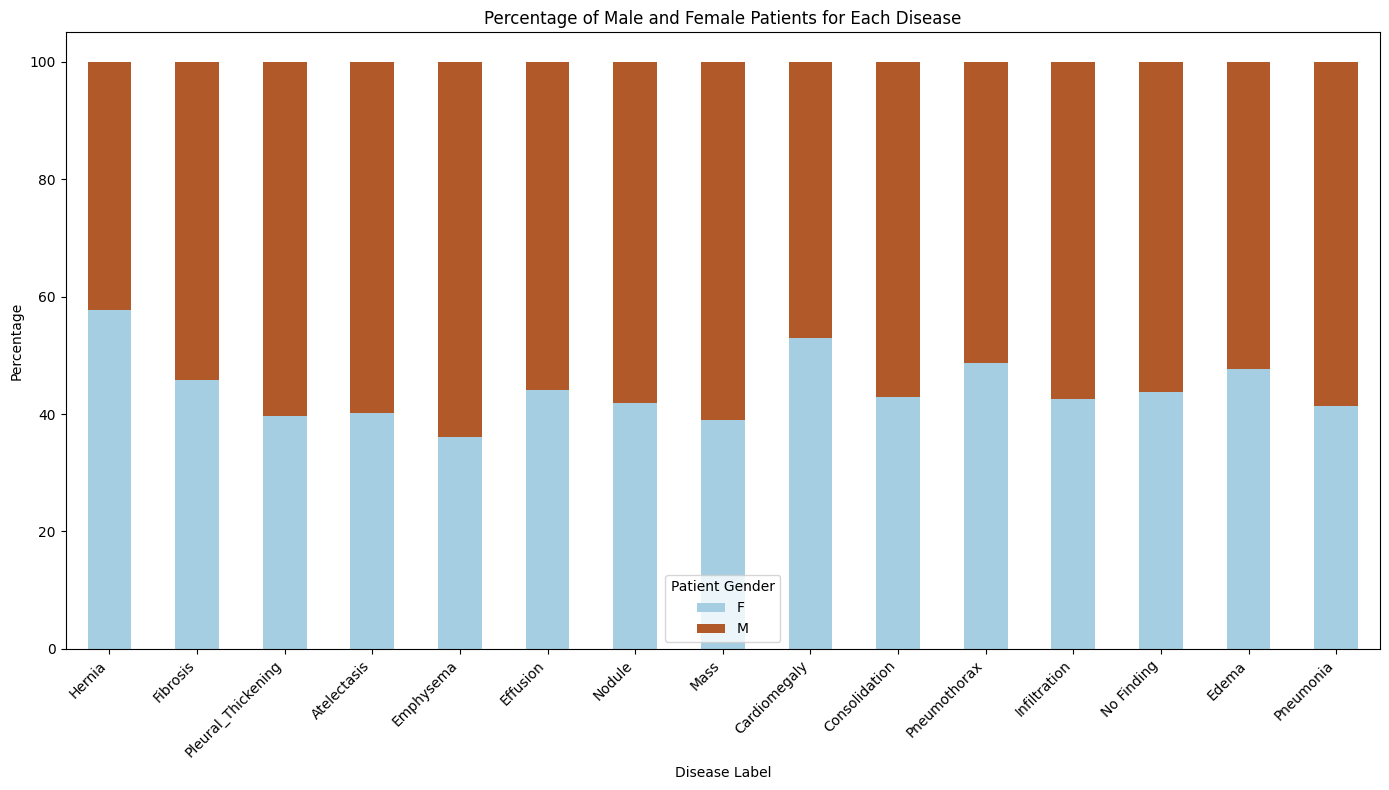

In [17]:
# Group by 'Finding Labels' and 'Patient Gender' to get counts, then unstack to create separate columns for male and female counts
gender_distribution = df_disease_analysis_exploded.groupby(['Finding Labels', 'Patient Gender']).size().unstack(fill_value=0)

# Calculate the percentage of each gender for each disease, converting counts to proportions
gender_distribution_percentage = gender_distribution.apply(lambda x: x / x.sum() * 100, axis=1)

# Reindex the gender distribution DataFrame to match the order of diseases sorted by average age (from previous analysis)
gender_distribution_percentage = gender_distribution_percentage.reindex(avg_age_per_disease.index)

# Create a stacked bar plot to visualize gender distribution per disease
plt.figure(figsize=(14, 8))
gender_distribution_percentage.plot(kind='bar', stacked=True, figsize=(14, 8), cmap='Paired')
plt.title('Percentage of Male and Female Patients for Each Disease')
plt.xlabel('Disease Label')
plt.ylabel('Percentage')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.legend(title='Patient Gender') # Add a legend for genders (Male/Female)
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

### 4.7 Image Path Mapping

This subsection is responsible for mapping each image index to its full path within the `data.zip` file. This mapping is essential for efficiently loading individual images directly from the compressed archive during dataset creation and training.

In [18]:
print("Mapping images to their paths...")

# Initialize a dictionary to store the mapping from image index (filename) to its full path within the zip file
image_to_path = {}

# Check if the zip file exists before attempting to open it
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as z:
        # Iterate through all files and directories in the zip archive
        for filename_in_archive in z.namelist():
            # Check if the file is a PNG image and is located within one of the predefined image directories
            if filename_in_archive.endswith('.png') and any(filename_in_archive.startswith(prefix) for prefix in image_directory_prefixes):
                # Extract the base filename (e.g., '00000001_000.png') which serves as the 'Image Index'
                base_name = os.path.basename(filename_in_archive)
                # Store the mapping: base filename -> full path within the zip
                image_to_path[base_name] = filename_in_archive

# Map the 'Image Index' column in the DataFrame to the full paths within the zip file using the created dictionary
df['Image Path'] = df['Image Index'].map(image_to_path)

Mapping images to their paths...


In [19]:
print("Checking all image paths...")

found_images = 0
missing_images = 0

# Open the zip file once
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    # Get a list of all files within the zip for efficient checking
    zip_contents = set(zip_ref.namelist())

    # Iterate through each image path in the DataFrame
    for img_path in df['Image Path']:
        if img_path in zip_contents:
            found_images += 1
        else:
            missing_images += 1

print(f"Total images in DataFrame: {len(df)}")
print(f"Images found in zip: {found_images}")
print(f"Images missing from zip: {missing_images}")

# Optional: display some missing paths if any
if missing_images > 0:
    print("\nExample missing image paths:")
    missing_paths_sample = df[~df['Image Path'].isin(zip_contents)]['Image Path'].head(5).tolist()
    for path in missing_paths_sample:
        print(f"- {path}")


Checking all image paths...
Total images in DataFrame: 112120
Images found in zip: 112120
Images missing from zip: 0


In [20]:
df = df[['Finding Labels', 'Patient ID', 'Image Path']]
df

,Finding Labels,Patient ID,Image Path
0,Cardiomegaly,1,images_001/images/00000001_000.png
1,Cardiomegaly|Emphysema,1,images_001/images/00000001_001.png
2,Cardiomegaly|Effusion,1,images_001/images/00000001_002.png
3,No Finding,2,images_001/images/00000002_000.png
4,Hernia,3,images_001/images/00000003_000.png
...,...,...,...
112115,Mass|Pneumonia,30801,images_012/images/00030801_001.png
112116,No Finding,30802,images_012/images/00030802_000.png
112117,No Finding,30803,images_012/images/00030803_000.png
112118,No Finding,30804,images_012/images/00030804_000.png


## 5. Visualize Random Image
This section focuses on displaying a randomly selected set of images directly from the `data.zip` file, along with their associated disease labels. This provides a quick visual inspection of the dataset and confirms the image loading and label mapping functionality.

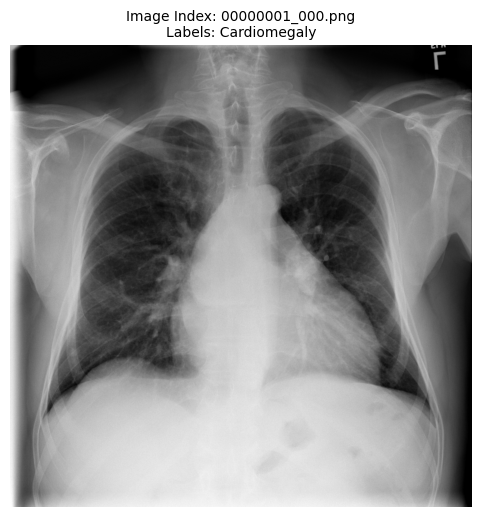

In [27]:
def display_image_from_zip(df_row_index, dataframe, zip_path, ax=None):
    """
    Displays an image directly from a zip file based on its row index in a DataFrame.

    The image is loaded from the specified zip_path using the 'Image Path' column
    of the DataFrame. It converts the image to grayscale and displays it with
    its associated labels as the title.

    Args:
        df_row_index (int): The index of the row in the DataFrame corresponding to the image.
        dataframe (pd.DataFrame): The DataFrame containing image metadata, including 'Image Path' and 'Finding Labels'.
        zip_path (str): The full path to the zip file containing the images.
        ax (matplotlib.axes.Axes, optional): The axes object to plot the image on.
                                            If None, a new figure and axes will be created.
    """
    # Validate the provided DataFrame row index
    if df_row_index >= len(dataframe) or df_row_index < 0:
        print(f"Error: Index {df_row_index} is out of bounds for the dataframe.")
        return

    # Retrieve row data for the specified image
    row = dataframe.iloc[df_row_index]
    path_inside_zip = row['Image Path']
    finding_labels = row['Finding Labels']

    try:
        # Open the zip file, read the image data into memory, and then open with PIL
        with zipfile.ZipFile(zip_path, 'r') as zf:
            image_data = zf.read(path_inside_zip)
            image = Image.open(io.BytesIO(image_data)).convert('L') # Convert to grayscale

        # Create a new subplot if no axes are provided
        if ax is None:
            fig, ax = plt.subplots(figsize=(6, 6))

        # Display the image
        ax.imshow(image, cmap='gray')
        # Derive image index from the path for the title, as 'Image Index' column may not exist
        image_index_for_title = os.path.basename(path_inside_zip)
        ax.set_title(f"Image Index: {image_index_for_title}\nLabels: {finding_labels}", fontsize=10)
        ax.set_axis_off()

    except KeyError:
        # If the previous check confirms file existence, this error indicates a deeper issue.
        print(f"Critical Error: Image '{path_inside_zip}' was expected to be in the zip but caused a KeyError. Cannot display image.")
        return # Exit the function if image loading fails
    except Exception as e:
        print(f"An unexpected error occurred while loading image '{path_inside_zip}': {e}")
        return # Exit the function if any other error occurs

# Example usage: display the first image in the DataFrame
display_image_from_zip(0, df, zip_path)
plt.show()

Displaying 9 random images from the dataset:


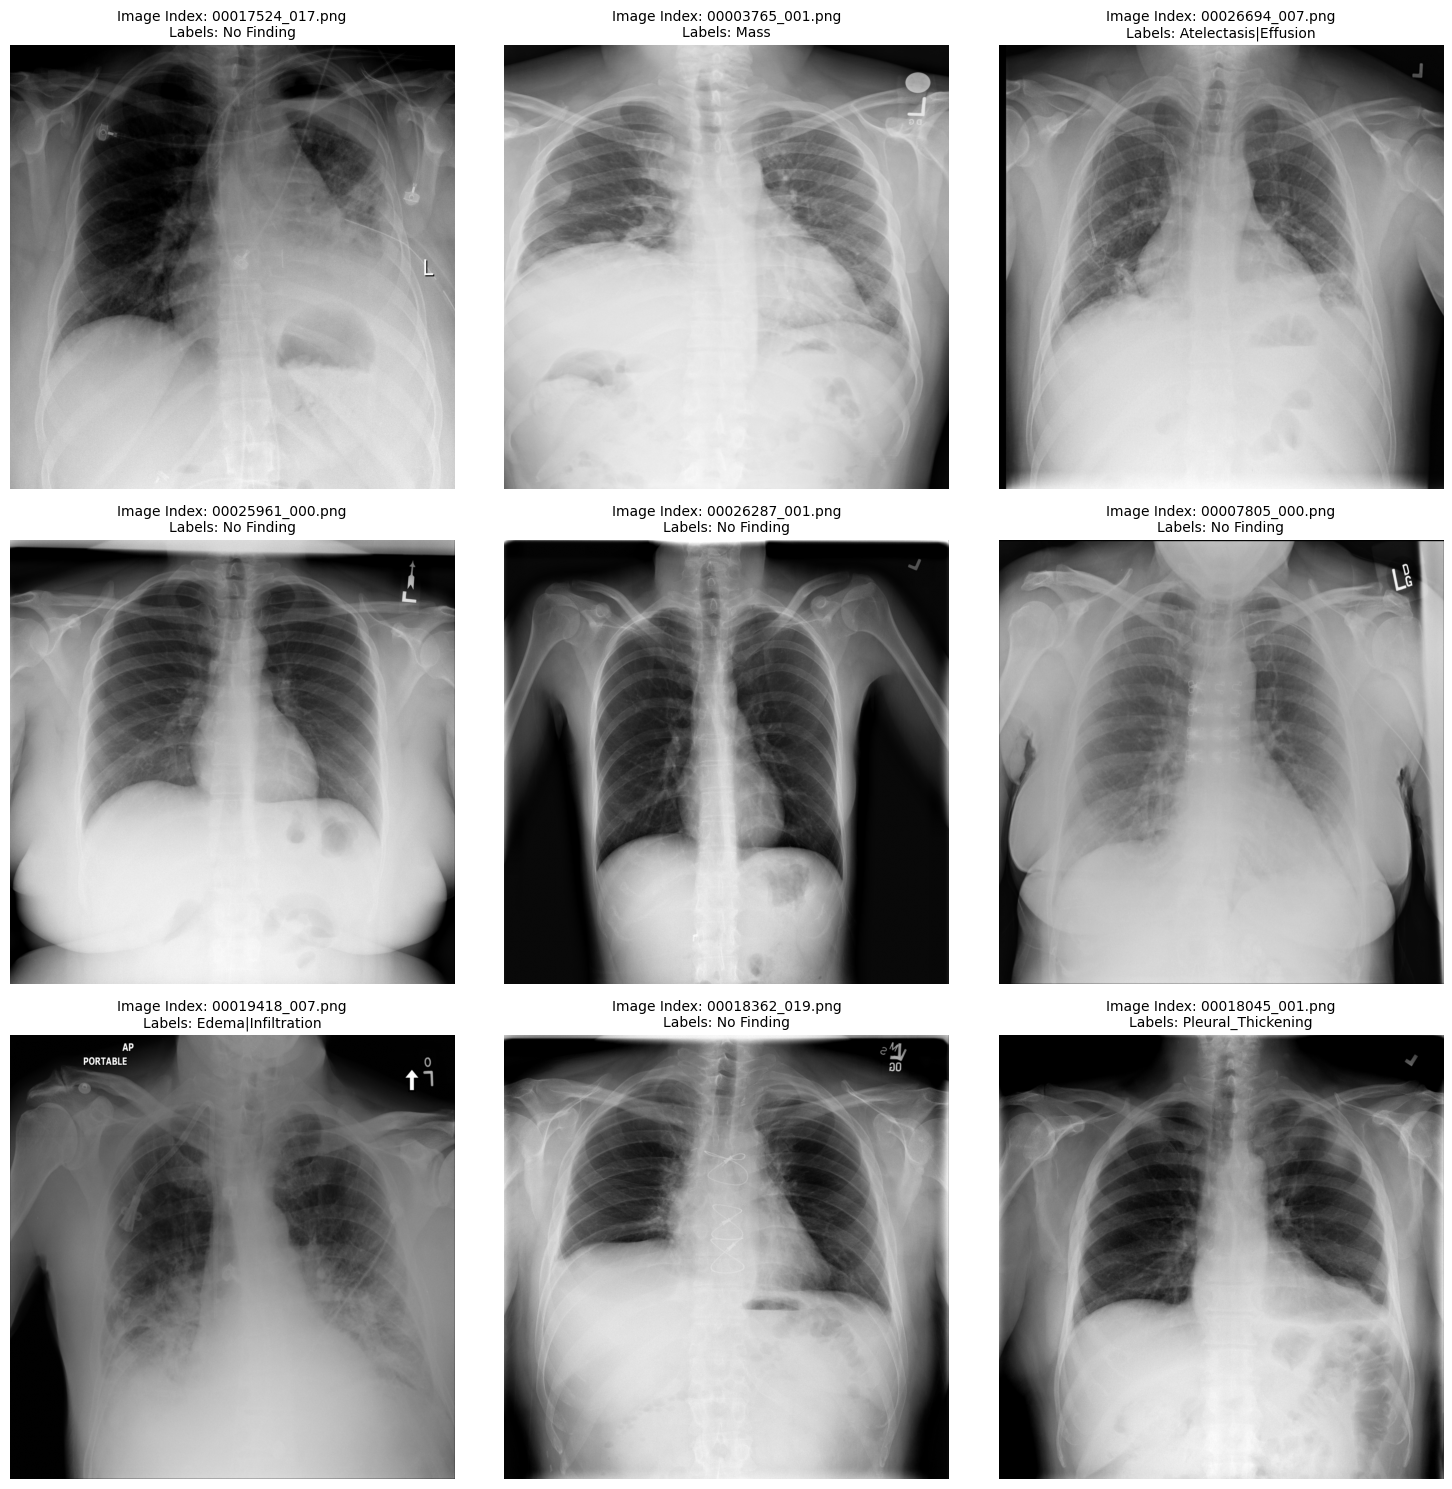

In [28]:
# Define the number of random images to plot
num_images_to_plot = 9

# Handle cases where the DataFrame is empty or has fewer images than requested
if len(df) == 0:
    print("The DataFrame is empty. Cannot plot any images.")
    # Exit or handle this case as appropriate
elif len(df) < num_images_to_plot:
    print(f"Warning: DataFrame has only {len(df)} images. Plotting all available images.")
    # If fewer images exist than requested, plot all of them
    sampled_indices = df.index.tolist()
else:
    # Randomly sample indices from the DataFrame for displaying a subset of images
    sampled_indices = random.sample(df.index.tolist(), num_images_to_plot)

print(f"Displaying {len(sampled_indices)} random images from the dataset:")

# Create a figure and a grid of subplots for the images (3x3 grid for 9 images)
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

# Iterate through sampled indices and display each image using the helper function
for i, idx in enumerate(sampled_indices):
    display_image_from_zip(idx, df, zip_path, ax=axes[i])

# Remove any unused subplots if fewer images were plotted than `num_images_to_plot` (e.g., if df had < 9 images)
for j in range(len(sampled_indices), num_images_to_plot):
    fig.delaxes(axes[j])

plt.tight_layout() # Adjust layout to prevent overlapping titles/labels
plt.show()

## 6. Data Pipeline

In [21]:
# Build the fixed, sorted list of pathologies (exclude "No Finding").
ALL_LABELS = sorted([l for l in set(all_disease_appearances) if l != "No Finding"])
NUM_CLASSES = len(ALL_LABELS)
print(f"Number of classes: {NUM_CLASSES}")
print(ALL_LABELS)

Number of classes: 14
['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Effusion', 'Emphysema', 'Fibrosis', 'Hernia', 'Infiltration', 'Mass', 'Nodule', 'Pleural_Thickening', 'Pneumonia', 'Pneumothorax']


## 6.1 Patient-level Train / Val / Test split (70/15/15)
Splitting by **patient ID** (not by image) prevents the same patient appearing in both train and validation — a common source of overly-optimistic metrics. We hold out a separate **test** set for the final unbiased report, and pre-compute the per-class one-hot columns used by the loss/metrics.

In [22]:
# Split unique patients: 70% train, 15% val, 15% test (temp split then halved).
unique_patients = df["Patient ID"].unique()
train_patients, temp_patients = train_test_split(unique_patients, test_size=0.30, random_state=42)
val_patients, test_patients = train_test_split(temp_patients, test_size=0.50, random_state=42)

# Build per-split DataFrames (reset index for clean .loc indexing downstream).
train_df = df[df["Patient ID"].isin(train_patients)].reset_index(drop=True)
val_df   = df[df["Patient ID"].isin(val_patients)].reset_index(drop=True)
test_df  = df[df["Patient ID"].isin(test_patients)].reset_index(drop=True)

print(f"Train: {len(train_df)} imgs / {train_df['Patient ID'].nunique()} patients")
print(f"Val  : {len(val_df)} imgs / {val_df['Patient ID'].nunique()} patients")
print(f"Test : {len(test_df)} imgs / {test_df['Patient ID'].nunique()} patients")

Train: 78566 imgs / 21563 patients
Val  : 17063 imgs / 4621 patients
Test : 16491 imgs / 4621 patients


## 6.2 Transforms & Augmentation (X-ray safe)
The backbone loaded here — `ViT_B_16_Weights.DEFAULT` = torchvision's **IMAGENET1K_V1** — was trained (modified DeiT recipe) with **ImageNet stats** (`mean=[0.485,0.456,0.406]`, `std=[0.229,0.224,0.225]`). Matching pre-training statistics keeps fine-tuning in-distribution.

Each augmentation is **anatomy-preserving** for chest X-rays:
- `RandomResizedCrop(0.85–1.0)` — mild zoom only (lungs must stay in frame).
- `RandomHorizontalFlip` — left/right is roughly symmetric in frontal CXR.
- `RandomAffine(±10°, small translate/scale)` — mimics patient positioning variation.
- `ColorJitter(brightness/contrast)` — exposure differences across machines.
- `RandomAdjustSharpness` — sensor/sharpness variation.
> Validation/test use a deterministic `Resize → ToTensor → Normalize` (no randomness).

In [23]:
# Normalization stats of the pre-trained ViT backbone (see markdown note above).
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
IMG_SIZE = 224

# --- Training-time augmentation pipeline (random, X-ray-safe) ---
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),                                # square base size
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0)),              # mild zoom-in only
    transforms.RandomHorizontalFlip(p=0.5),                                 # frontal CXR ~ L/R symmetric
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),  # positioning
    transforms.ColorJitter(brightness=0.15, contrast=0.15),                 # exposure/contrast
    transforms.RandomAdjustSharpness(0.5, p=0.2),                           # sharpness variation
    transforms.ToTensor(),                                                  # -> tensor in [0,1]
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),             # match backbone stats
])

# --- Deterministic evaluation pipeline (no randomness) ---
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

## 6.3 Datasets & DataLoaders
Images are **streamed directly from `data.zip`** (no 45 GB extraction). Each DataLoader worker opens its **own** zip handle (`worker_init_fn`) to avoid file-descriptor sharing. `persistent_workers=True` keeps workers alive between epochs, and `drop_last=True` on the train loader keeps batch statistics stable.

In [24]:
def worker_init_fn(worker_id):
    """Open a dedicated zip handle inside each DataLoader worker process.

    Sharing one ``ZipFile`` across forked workers corrupts reads; giving each
    worker its own handle avoids that. Called automatically per worker.
    """
    wi = torch.utils.data.get_worker_info()
    if wi is not None:
        wi.dataset._zipfile = zipfile.ZipFile(wi.dataset.data_zip_path, "r")

In [25]:
class SmartChestDatasetV2(Dataset):
    """Stream chest X-rays + multi-hot labels straight from ``data.zip``.

    Uses the FIXED ``ALL_LABELS`` order so labels are resume-safe.

    Args:
        dataframe (pd.DataFrame): Metadata with ``Image Path`` and ``Finding Labels``.
        download_path (str): Directory that contains ``data.zip``.
        transform (callable, optional): Image transform pipeline.
        label_list (list[str]): Ordered list of class names (index = output neuron).
    """

    def __init__(self, dataframe, download_path, transform=None, label_list=None):
        self.df = dataframe.reset_index(drop=True)
        self.download_path = download_path
        self.transform = transform
        self.labels = label_list
        self.data_zip_path = os.path.join(download_path, "data.zip")
        self._zipfile = None  # opened lazily per-process / per-worker

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Lazily open the zip in this process (fallback if worker_init_fn not used).
        if self._zipfile is None:
            self._zipfile = zipfile.ZipFile(self.data_zip_path, "r")
        path = self.df.loc[idx, "Image Path"]
        try:
            with self._zipfile.open(path) as f:
                image = Image.open(f).convert("RGB")
        except Exception:
            image = Image.new("RGB", (IMG_SIZE, IMG_SIZE), (0, 0, 0))  # black placeholder

        # Multi-hot target vector in the fixed label order.
        lv = torch.zeros(len(self.labels), dtype=torch.float32)
        s = self.df.loc[idx, "Finding Labels"]
        for i, l in enumerate(self.labels):
            if l in s:
                lv[i] = 1.0

        image = self.transform(image) if self.transform else transforms.ToTensor()(image)
        return image, lv

In [26]:
# --- Build the three datasets ---
train_dataset = SmartChestDatasetV2(train_df, download_path, transform=train_transform, label_list=ALL_LABELS)
val_dataset   = SmartChestDatasetV2(val_df,   download_path, transform=eval_transform,  label_list=ALL_LABELS)
test_dataset  = SmartChestDatasetV2(test_df,  download_path, transform=eval_transform,  label_list=ALL_LABELS)

In [27]:
# --- Sanity checks: shapes + batch counts + one preview image ---
img0, lbl0 = train_dataset[0]
print(f"single sample -> image {tuple(img0.shape)} | label {tuple(lbl0.shape)}")

single sample -> image (3, 224, 224) | label (14,)


In [28]:
BATCH_SIZE      = 64
NUM_WORKERS     = 2

# --- DataLoaders (batch 64, pinned memory, persistent per-worker zip handles) ---
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=False,
                          worker_init_fn=worker_init_fn, drop_last=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=False,
                          worker_init_fn=worker_init_fn)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=False,
                          worker_init_fn=worker_init_fn)

In [29]:
print(f"Batches -> train:{len(train_loader)} val:{len(val_loader)} test:{len(test_loader)}")

Batches -> train:1227 val:267 test:258


In [40]:
image = next(iter(train_loader))[0][0]   # peek at one augmented image tensor
image

tensor([[[-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         ...,
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1008],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1008],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.0837]],

        [[-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         ...,
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0182],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0182],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0007]],

        [[-1.8044, -1.8044, -1.8044,  ..., -1.8044, -1.8044, -1.8044],
         [-1.8044, -1.8044, -1.8044,  ..., -1

## 7. Model — ViT-B/16 with a partial fine-tune + MLP head
- **Backbone:** `vit_b_16` (ImageNet-1K pre-trained).
- **Fine-tuning:** only the **last 4 encoder blocks** and the **final encoder LayerNorm** are trainable — enough capacity to adapt to X-rays without overfitting / long epochs. Everything earlier stays frozen.
- **Head:** `Linear(768→512) → GELU → Dropout → Linear(512→14)` — a stronger multi-label classifier than a single Linear.

In [30]:
UNFREEZE_LAST   = 4
HEAD_DROPOUT    = 0.3

class ChestViT(nn.Module):
    """ViT-B/16 backbone with the last ``unfreeze_last`` encoder blocks (+ final
    LayerNorm) trainable, and an MLP head for multi-label classification.

    Args:
        num_classes (int): Number of disease labels (output logits).
        unfreeze_last (int): How many trailing encoder blocks to fine-tune.
        head_dropout (float): Dropout probability inside the MLP head.
    """

    def __init__(self, num_classes=14, unfreeze_last=UNFREEZE_LAST, head_dropout=HEAD_DROPOUT):
        super().__init__()
        self.backbone = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

        # 1) Freeze the whole backbone ...
        for p in self.backbone.parameters():
            p.requires_grad = False
        # 2) ... then unfreeze the last N encoder blocks ...
        for blk in self.backbone.encoder.layers[-unfreeze_last:]:
            for p in blk.parameters():
                p.requires_grad = True
        # 3) ... and the final encoder LayerNorm (cheap, helps adaptation).
        for p in self.backbone.encoder.ln.parameters():
            p.requires_grad = True

        # 4) Replace the classifier with an MLP head (always trainable).
        in_f = self.backbone.heads.head.in_features
        self.backbone.heads.head = nn.Sequential(
            nn.Linear(in_f, 512),
            nn.GELU(),
            nn.Dropout(head_dropout),
            nn.Linear(512, num_classes))

        for p in self.backbone.heads.head.parameters():
            p.requires_grad = True

    def forward(self, x):
        """Run the backbone and return raw logits of shape ``(B, num_classes)``."""
        return self.backbone(x)

In [31]:
# Instantiate the model and move it to GPU/CPU.
model = ChestViT(num_classes=NUM_CLASSES).to(device)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:06<00:00, 55.3MB/s]


In [ ]:
# Full layer-by-layer architecture summary.
summary(model, (1, 3, IMG_SIZE, IMG_SIZE))

Layer (type:depth-idx)                             Output Shape              Param #
ChestViT                                           [1, 14]                   --
├─VisionTransformer: 1-1                           [1, 14]                   768
│    └─Conv2d: 2-1                                 [1, 768, 14, 14]          (590,592)
│    └─Encoder: 2-2                                [1, 197, 768]             151,296
│    │    └─Dropout: 3-1                           [1, 197, 768]             --
│    │    └─Sequential: 3-2                        [1, 197, 768]             85,054,464
│    │    └─LayerNorm: 3-3                         [1, 197, 768]             1,536
│    └─Sequential: 2-3                             [1, 14]                   --
│    │    └─Sequential: 3-4                        [1, 14]                   400,910
Total params: 86,199,566
Trainable params: 28,753,934
Non-trainable params: 57,445,632
Total mult-adds (Units.MEGABYTES): 172.86
Input size (MB): 0.60
Forward/backwar

## 8. Loss — Asymmetric Loss (ASL)
ChestX-ray14 is heavily imbalanced (~60% "No Finding"; Hernia < 0.2%). Standard weighted BCE still lets **easy negatives dominate** the gradient. **ASL** (Ridnik et al., 2021) fixes this by using different focusing for positives vs. negatives:
- `gamma_neg` (≈4) strongly down-weights easy negatives.
- `gamma_pos` (≈1) keeps a mild focus on the rare positives.
- `clip` shifts negative probabilities, discarding very-easy negatives entirely.

In [32]:
ASL_GAMMA_NEG   = 4
ASL_GAMMA_POS   = 1
ASL_CLIP        = 0.05

class AsymmetricLoss(nn.Module):
    """Asymmetric Loss for multi-label classification with class imbalance.

    Down-weights easy negatives (``gamma_neg``) so the model focuses on the
    hard / rare positive findings instead of the flood of negatives.

    Args:
        gamma_neg (float): Focusing parameter for negative samples.
        gamma_pos (float): Focusing parameter for positive samples.
        clip (float): Probability shift applied to negatives (hard-negative filter).
        eps (float): Numerical-stability epsilon for the logs.
    """

    def __init__(self, gamma_neg=ASL_GAMMA_NEG, gamma_pos=ASL_GAMMA_POS, clip=ASL_CLIP, eps=1e-8):
        super().__init__()
        self.gamma_neg, self.gamma_pos, self.clip, self.eps = gamma_neg, gamma_pos, clip, eps

    def forward(self, logits, targets):
        """Compute the loss. ``logits``/``targets`` have shape ``(B, C)``."""
        x_sig = torch.sigmoid(logits)
        xs_pos, xs_neg = x_sig, 1 - x_sig
        if self.clip and self.clip > 0:
            xs_neg = (xs_neg + self.clip).clamp(max=1)   # discard very-easy negatives
        loss = targets * torch.log(xs_pos.clamp(min=self.eps)) + \
               (1 - targets) * torch.log(xs_neg.clamp(min=self.eps))
        if self.gamma_neg > 0 or self.gamma_pos > 0:
            pt = xs_pos * targets + xs_neg * (1 - targets)
            gamma = self.gamma_pos * targets + self.gamma_neg * (1 - targets)
            loss *= torch.pow(1 - pt, gamma)             # asymmetric focusing
        return -loss.mean()

# Instantiate the criterion with the config values.
criterion = AsymmetricLoss(gamma_neg=ASL_GAMMA_NEG, gamma_pos=ASL_GAMMA_POS, clip=ASL_CLIP)

## 9. Optimizer & LR Schedule
- **AdamW** (`weight_decay=0.05`) for regularization-friendly updates.
- **Discriminative LR:** the new head trains faster (`1e-3`) than the pre-trained backbone (`1e-4`), so we don't wreck the learned features.
- **Linear warmup → Cosine decay** to 0 over `EPOCHS`.
- **Gradient clipping** (`max_norm=1.0`) keeps AMP updates stable.

In [33]:
EPOCHS = 15
HEAD_LR = 1e-3
BACKBONE_LR = 1e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 1
GRAD_CLIP = 1.0

# ---- Parameter groups: backbone (slow) vs. head (fast) ----
head_params     = [p for n, p in model.named_parameters() if "heads.head" in n and p.requires_grad]
backbone_params = [p for n, p in model.named_parameters() if "heads.head" not in n and p.requires_grad]

optimizer = torch.optim.AdamW(
    [{"params": backbone_params, "lr": BACKBONE_LR},
     {"params": head_params,     "lr": HEAD_LR}],
    weight_decay=WEIGHT_DECAY)

# ---- Linear-warmup -> Cosine-decay schedule (step-based) ----
total_steps  = EPOCHS * len(train_loader)
warmup_steps = WARMUP_EPOCHS * len(train_loader)

def lr_lambda(step):
    """Warmup linearly to 1.0, then cosine-decay to 0.0 by the final step."""
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + np.cos(np.pi * prog))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler("cuda")   # mixed-precision gradient scaler
print(f"Total steps {total_steps}, warmup {warmup_steps}")

Total steps 18405, warmup 1227


## 10. Metric Helpers
For imbalanced multi-label data we track **macro Average Precision (mAP)** *and* **macro ROC-AUC**. mAP is more informative under class imbalance (it accounts for the positive rate), while AUC gives a threshold-independent ranking view. Classes with no positives in a batch/split are skipped.

In [34]:
def compute_metrics(targets, preds):
    """Compute macro-AP and macro-AUC over the classes that have positives.

    Args:
        targets (np.ndarray): Ground-truth multi-hot matrix, shape ``(N, C)``.
        preds (np.ndarray): Predicted probabilities in ``[0,1]``, shape ``(N, C)``.

    Returns:
        tuple[float, float]: ``(macro_AP, macro_AUC)``.
    """
    aps, aucs = [], []
    for c in range(targets.shape[1]):
        if targets[:, c].sum() == 0:      # skip classes with no positive sample
            continue
        aps.append(average_precision_score(targets[:, c], preds[:, c]))
        try:
            aucs.append(roc_auc_score(targets[:, c], preds[:, c]))
        except ValueError:                 # AUC undefined if a class is all-one-label
            pass
    return float(np.mean(aps)), float(np.mean(aucs))

## 11. Train / Validation Epoch Functions
One training epoch uses **mixed precision** (autocast + GradScaler), **gradient clipping**, and a **step-based LR scheduler**. The evaluation epoch runs under `torch.inference_mode()` and returns the stacked predictions/targets so the test cell can build the full report.

In [35]:
LOG_EVERY = 100

def train_one_epoch(model, loader, optimizer, criterion, scaler, scheduler, device, clip=GRAD_CLIP):
    """Run one training epoch with AMP, gradient clipping and LR stepping.

    Args:
        model (nn.Module): The network to train.
        loader (DataLoader): Training DataLoader.
        optimizer (Optimizer): AdamW optimizer.
        criterion (nn.Module): Loss function (ASL).
        scaler (GradScaler): Mixed-precision gradient scaler.
        scheduler (LRScheduler): Step-based LR scheduler.
        device (torch.device): Compute device.
        clip (float): Max gradient norm for clipping.

    Returns:
        tuple[float, float, float]: ``(avg_loss, train_mAP, train_mAUC)``.
    """
    model.train()
    running, all_p, all_t = 0.0, [], []
    for i, (imgs, labels) in enumerate(loader):
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda"):
            out  = model(imgs)
            loss = criterion(out, labels)

        # Backprop with scaled gradients -> clip -> optimizer step -> scaler update.
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running += loss.item()
        all_p.append(torch.sigmoid(out).detach().float().cpu().numpy())
        all_t.append(labels.detach().float().cpu().numpy())
        if (i + 1) % LOG_EVERY == 0:
            print(f"  [train {i+1}/{len(loader)}] loss: {loss.item():.4f} | LR: {scheduler.get_last_lr()[0]:.2e}")

    mAP, mAUC = compute_metrics(np.vstack(all_t), np.vstack(all_p))
    return running / len(loader), mAP, mAUC

In [36]:
@torch.inference_mode()
def eval_one_epoch(model, loader, criterion, device):
    """Run one evaluation epoch (no gradient updates).

    Args:
        model (nn.Module): The network to evaluate.
        loader (DataLoader): Validation or test DataLoader.
        criterion (nn.Module): Loss function.
        device (torch.device): Compute device.

    Returns:
        tuple: ``(avg_loss, mAP, mAUC, preds, targets)`` where ``preds`` and
        ``targets`` are stacked ``(N, C)`` arrays for downstream reporting.
    """
    model.eval()
    running, all_p, all_t = 0.0, [], []
    for imgs, labels in loader:
        imgs   = imgs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.amp.autocast("cuda"):
            out  = model(imgs)
            loss = criterion(out, labels)
        running += loss.item()
        all_p.append(torch.sigmoid(out).float().cpu().numpy())
        all_t.append(labels.float().cpu().numpy())

    mAP, mAUC = compute_metrics(np.vstack(all_t), np.vstack(all_p))
    return running / len(loader), mAP, mAUC, np.vstack(all_p), np.vstack(all_t)

## 12. Google Drive Backup
Mount Drive so checkpoints survive a Colab VM reset. The training loop writes locally **and** mirrors to `DRIVE_DIR` every epoch. *(First run triggers a one-time auth popup.)*

In [37]:
import shutil
from google.colab import drive

drive.mount("/content/drive")                          # mount Google Drive
DRIVE_DIR = "/content/drive/MyDrive/chest_xray_run2"   # backup folder
os.makedirs(DRIVE_DIR, exist_ok=True)
print("Drive backup dir:", DRIVE_DIR)

Mounted at /content/drive
Drive backup dir: /content/drive/MyDrive/chest_xray_run2


## 13. Checkpoint Setup & Resume
Defines the local + Drive paths, **restores from Drive** if the VM was wiped, then loads a saved checkpoint (model / optimizer / scheduler / scaler / history) to resume exactly where training left off. If none exists, a fresh run starts.

In [38]:
# ---- Local (fast) checkpoint paths ----
save_dir  = os.path.join(download_path, "checkpoints_run2")
os.makedirs(save_dir, exist_ok=True)
ckpt_path = os.path.join(save_dir, "run2_checkpoint.pth")  # full resume state
best_path = os.path.join(save_dir, "run2_best.pth")        # best-by-mAP weights
# ---- Drive mirror paths ----
drive_ckpt = os.path.join(DRIVE_DIR, "run2_checkpoint.pth")
drive_best = os.path.join(DRIVE_DIR, "run2_best.pth")

# ---- Restore from Drive if the Colab VM was reset ----
if not os.path.exists(ckpt_path) and os.path.exists(drive_ckpt):
    shutil.copy2(drive_ckpt, ckpt_path); print("Restored training checkpoint from Drive.")
if not os.path.exists(best_path) and os.path.exists(drive_best):
    shutil.copy2(drive_best, best_path); print("Restored best model from Drive.")

# ---- Training state ----
start_epoch, best_mAP, patience_counter = 0, -1.0, 0
history = {"train_loss": [], "val_loss": [], "train_mAP": [], "val_mAP": [], "val_mAUC": []}

# ---- Resume if a checkpoint exists, else start fresh ----
if os.path.exists(ckpt_path):
    ck = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model_state"]);       optimizer.load_state_dict(ck["optimizer_state"])
    scheduler.load_state_dict(ck["scheduler_state"]); scaler.load_state_dict(ck["scaler_state"])
    start_epoch      = ck["epoch"] + 1
    best_mAP         = ck["best_mAP"]
    patience_counter = ck["patience_counter"]
    history          = ck["history"]
    print(f"Resumed from epoch {start_epoch} (best mAP {best_mAP:.4f})")
else:
    print("Starting training.")

Restored training checkpoint from Drive.
Restored best model from Drive.
Resumed from epoch 10 (best mAP 0.2088)


## 14. Training Loop
Trains up to `EPOCHS` epochs. Each epoch: train → validate → log metrics → **save best-by-mAP** (local + Drive) → **save full resume checkpoint** (local + Drive). **Early stopping** triggers when val mAP hasn't improved for `PATIENCE` epochs.

In [ ]:
EPOCHS = 15
PATIENCE = 3

print("Training started...\n")
for epoch in range(start_epoch, EPOCHS):
    print("=" * 60); print(f"Epoch [{epoch+1}/{EPOCHS}]"); print("=" * 60)

    # ---- train + validate one epoch ----
    tr_loss, tr_mAP, _= train_one_epoch(model, train_loader, optimizer, criterion, scaler, scheduler, device)
    va_loss, va_mAP, va_mAUC, _, _ = eval_one_epoch(model, val_loader, criterion, device)

    # ---- log metrics for later plotting ----
    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_mAP"].append(tr_mAP);   history["val_mAP"].append(va_mAP)
    history["val_mAUC"].append(va_mAUC)
    print(f"\nEpoch {epoch+1} | train_loss {tr_loss:.4f} mAP {tr_mAP:.4f} | "
          f"val_loss {va_loss:.4f} mAP {va_mAP:.4f} AUC {va_mAUC:.4f}")

    # ---- save the best model (by val mAP) locally + to Drive ----
    if va_mAP > best_mAP:
        best_mAP, patience_counter = va_mAP, 0
        torch.save({"model_state": model.state_dict(), "epoch": epoch, "mAP": va_mAP}, best_path)
        shutil.copy2(best_path, drive_best)
        print(f"  New best val mAP {va_mAP:.4f} -> saved best model (local + Drive).")
    else:
        patience_counter += 1
        print(f"  No mAP improvement. patience {patience_counter}/{PATIENCE}")

    # ---- save the full resume checkpoint locally + to Drive ----
    torch.save({"epoch": epoch, "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
                "scaler_state": scaler.state_dict(), "best_mAP": best_mAP,
                "patience_counter": patience_counter, "history": history}, ckpt_path)
    shutil.copy2(ckpt_path, drive_ckpt)
    print("  Checkpoint synced to Drive.")

    # ---- early stopping ----
    if patience_counter >= PATIENCE:
        print("Early stopping (val mAP stagnated)."); break

print("Training finished.")


Training started...

Epoch [7/15]
  [train 100/1227] loss: 0.0283 | LR: 7.09e-05
  [train 200/1227] loss: 0.0240 | LR: 7.00e-05
  [train 300/1227] loss: 0.0174 | LR: 6.92e-05
  [train 400/1227] loss: 0.0222 | LR: 6.83e-05
  [train 500/1227] loss: 0.0260 | LR: 6.75e-05
  [train 600/1227] loss: 0.0264 | LR: 6.66e-05
  [train 700/1227] loss: 0.0244 | LR: 6.58e-05
  [train 800/1227] loss: 0.0258 | LR: 6.49e-05
  [train 900/1227] loss: 0.0212 | LR: 6.40e-05
  [train 1000/1227] loss: 0.0242 | LR: 6.31e-05
  [train 1100/1227] loss: 0.0206 | LR: 6.23e-05
  [train 1200/1227] loss: 0.0250 | LR: 6.14e-05

Epoch 7 | train_loss 0.0247 mAP 0.2995 | val_loss 0.0267 mAP 0.2088 AUC 0.8086
  New best val mAP 0.2088 -> saved best model (local + Drive).
  Checkpoint synced to Drive.
Epoch [8/15]
  [train 100/1227] loss: 0.0233 | LR: 6.02e-05
  [train 200/1227] loss: 0.0252 | LR: 5.93e-05
  [train 300/1227] loss: 0.0191 | LR: 5.84e-05
  [train 400/1227] loss: 0.0212 | LR: 5.75e-05
  [train 500/1227] loss: 

## 15. Training Curves
Loss, mAP (train/val) and val macro-AUC per epoch. **Healthy run:** val mAP and val AUC rise together and plateau; a growing train–val mAP gap signals overfitting (raise augmentation / dropout).

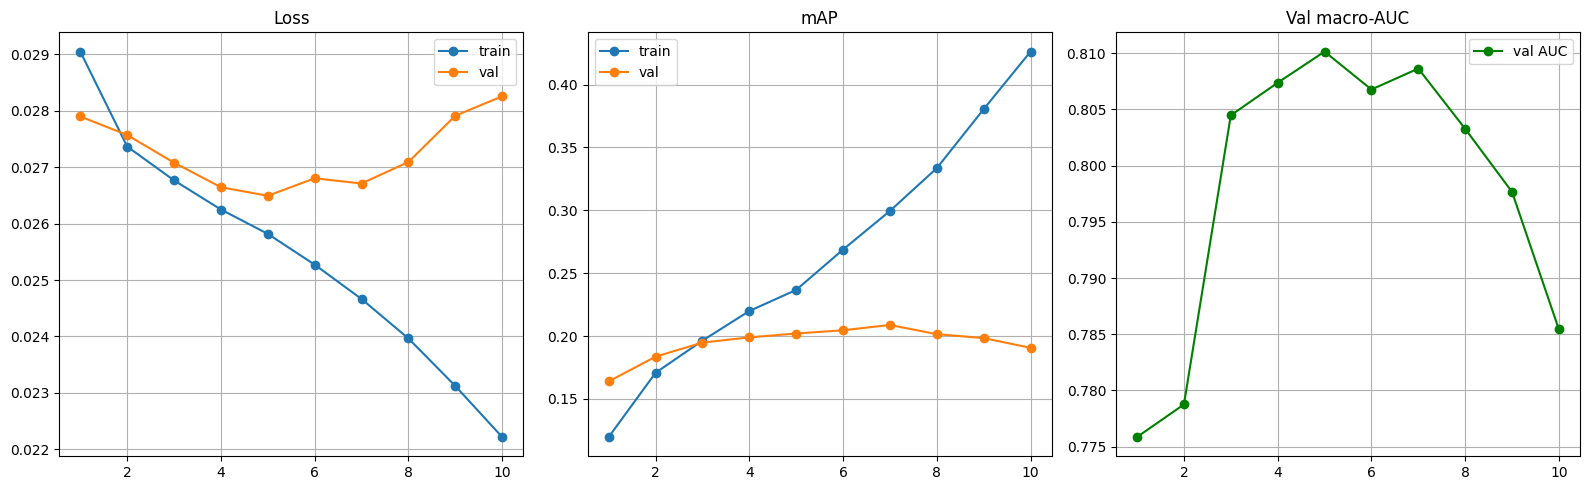

In [ ]:
ep = range(1, len(history["train_loss"]) + 1)
plt.figure(figsize=(16, 5))
plt.subplot(1, 3, 1); plt.plot(ep, history["train_loss"], "o-", label="train"); plt.plot(ep, history["val_loss"], "o-", label="val"); plt.title("Loss"); plt.legend(); plt.grid(True)
plt.subplot(1, 3, 2); plt.plot(ep, history["train_mAP"], "o-", label="train"); plt.plot(ep, history["val_mAP"], "o-", label="val"); plt.title("mAP"); plt.legend(); plt.grid(True)
plt.subplot(1, 3, 3); plt.plot(ep, history["val_mAUC"], "o-", label="val AUC", color="green"); plt.title("Val macro-AUC"); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.show()


## 16. Threshold Fine Tuning

**Per-class threshold tuning** — pick the F1-maximizing threshold per disease on validation set.

In [50]:
# ---- Load the best model (highest val mAP) ----
best = torch.load(best_path, map_location=device)
model.load_state_dict(best["model_state"])
print(f"Loaded best model (epoch {best['epoch']+1}, val mAP {best['mAP']:.4f})")

# ---- Evaluate on the validation set to determine F1-maximizing thresholds ----
print("\nEvaluating on validation set to find F1-maximizing thresholds...")
val_loss, val_mAP_for_threshold, val_mAUC_for_threshold, val_preds_for_threshold, val_targets_for_threshold = eval_one_epoch(model, val_loader, criterion, device)

thr_f1 = np.zeros(NUM_CLASSES)
for c in range(NUM_CLASSES):
    y, p = val_targets_for_threshold[:, c], val_preds_for_threshold[:, c]
    best_f1, best_t = 0, 0.5
    for t in np.linspace(0.1, 0.9, 33):
        try:
            f = f1_score(y, (p >= t).astype(int), zero_division=0)
        except ValueError:
            f = 0
        if f > best_f1:
            best_f1, best_t = f, t
    thr_f1[c] = best_t
print("F1-maximizing thresholds determined on validation set.")

Loaded best model (epoch 7, val mAP 0.2088)

Evaluating on validation set to find F1-maximizing thresholds...
F1-maximizing thresholds determined on validation set.


In [51]:
print("\nF1-maximizing thresholds (from validation set):")
for i, label in enumerate(ALL_LABELS):
    print(f"  {label}: {thr_f1[i]:.4f}")


F1-maximizing thresholds (from validation set):
  Atelectasis: 0.5250
  Cardiomegaly: 0.5250
  Consolidation: 0.5000
  Edema: 0.5000
  Effusion: 0.5750
  Emphysema: 0.4500
  Fibrosis: 0.4750
  Hernia: 0.4500
  Infiltration: 0.5500
  Mass: 0.5250
  Nodule: 0.4750
  Pleural_Thickening: 0.4750
  Pneumonia: 0.4750
  Pneumothorax: 0.5000


In [52]:
# Define the path to save the thresholds in the Google Drive directory
thresholds_save_path = os.path.join(DRIVE_DIR, 'f1_thresholds.npy')

# Save the thr_f1 (F1-maximizing thresholds) numpy array to the specified path
np.save(thresholds_save_path, thr_f1)

print(f"F1-maximizing thresholds saved to: {thresholds_save_path}")

F1-maximizing thresholds saved to: /content/drive/MyDrive/chest_xray_run2/f1_thresholds.npy


In [39]:
# Define the path to the saved thresholds in the Google Drive directory
thresholds_save_path = os.path.join(DRIVE_DIR, 'f1_thresholds.npy')

# Load the thr_f1 (F1-maximizing thresholds) numpy array from the specified path
if os.path.exists(thresholds_save_path):
    loaded_thr_f1 = np.load(thresholds_save_path)
    print(f"F1-maximizing thresholds loaded from: {thresholds_save_path}")
    print("Loaded thresholds (first 5 values):", loaded_thr_f1[:5])
else:
    print(f"Error: Threshold file not found at {thresholds_save_path}")


F1-maximizing thresholds loaded from: /content/drive/MyDrive/chest_xray_run2/f1_thresholds.npy
Loaded thresholds (first 5 values): [0.525 0.525 0.5   0.5   0.575]


## 17. Final Test Evaluation
Loads the **best-by-mAP** weights and reports on the held-out **test** set:
**Per-class AUC / AP** table (sorted) with positive counts.


In [ ]:
# ---- Full test-set pass ----
print("\nEvaluating on test set with validation-derived thresholds...")
test_loss, test_mAP, test_mAUC, test_preds, test_targets = eval_one_epoch(model, test_loader, criterion, device)
print(f"TEST  mAP {test_mAP:.4f} | macro-AUC {test_mAUC:.4f}")

# ---- Per-class AUC / AP table ----
rows = []
for c, lbl in enumerate(ALL_LABELS):
    y, p = test_targets[:, c], test_preds[:, c]
    if y.sum() == 0:
        rows.append((lbl, np.nan, np.nan, 0)); continue
    rows.append((lbl, roc_auc_score(y, p), average_precision_score(y, p), int(y.sum())))
report = pd.DataFrame(rows, columns=["Label", "AUC", "AP", "Positives"]).sort_values("AP", ascending=False)
display(report)

# ---- Apply F1-maximizing thresholds (from validation set) to test set predictions ----
y_bin_f1 = (test_preds >= loaded_thr_f1).astype(int)
print(f"Micro-F1 {f1_score(test_targets, y_bin_f1, average='micro', zero_division=0):.4f} | "
      f"Macro-F1 {f1_score(test_targets, y_bin_f1, average='macro', zero_division=0):.4f}")
print(f"Micro-P {precision_score(test_targets, y_bin_f1, average='micro', zero_division=0):.4f} | "
      f"Micro-R {recall_score(test_targets, y_bin_f1, average='micro', zero_division=0):.4f}")


Evaluating on test set with validation-derived thresholds...
TEST  mAP 0.2203 | macro-AUC 0.8081


,Label,AUC,AP,Positives
4,Effusion,0.868318,0.489327,1892
8,Infiltration,0.698229,0.333465,2932
5,Emphysema,0.884203,0.307962,454
0,Atelectasis,0.787162,0.304273,1677
13,Pneumothorax,0.851639,0.301490,725
1,Cardiomegaly,0.886218,0.266367,439
9,Mass,0.783771,0.245198,727
10,Nodule,0.712154,0.167779,945
3,Edema,0.883759,0.149719,374
2,Consolidation,0.792008,0.140407,730


Micro-F1 0.3443 | Macro-F1 0.2779
Micro-P 0.2851 | Micro-R 0.4345


## 18. Making Prediction

In [ ]:
def get_predictions_for_image(dataframe, df_row_index, model, device, eval_transform, zip_path, all_labels, thr_f1):
    """Predicts disease labels for a single image and returns true and predicted labels.

    Args:
        dataframe (pd.DataFrame): DataFrame containing image metadata.
        df_row_index (int): Row index of the image in the DataFrame.
        model (nn.Module): The trained model.
        device (torch.device): Compute device.
        eval_transform (callable): Image transformation for evaluation.
        zip_path (str): Path to the data.zip file.
        all_labels (list[str]): List of all possible disease labels.
        thr_f1 (np.ndarray): F1-maximizing thresholds for each class.

    Returns:
        tuple[list[str], list[str]]: (true_labels, predicted_labels)
    """
    model.eval()

    # Retrieve image path and true labels from the DataFrame
    row = dataframe.iloc[df_row_index]
    path_inside_zip = row['Image Path']
    true_labels_str = row['Finding Labels']

    # Load and preprocess the image
    try:
        with zipfile.ZipFile(zip_path, 'r') as zf:
            with zf.open(path_inside_zip) as img_file:
                image = Image.open(img_file).convert("RGB")
        inp = eval_transform(image).unsqueeze(0).to(device)
    except Exception as e:
        print(f"Error loading image {path_inside_zip}: {e}")
        return [], []

    # Forward pass
    with torch.inference_mode():
        logits = model(inp)
    probs = torch.sigmoid(logits).cpu().numpy()[0]

    # Apply F1-maximizing thresholds to get binary predictions
    binary_predictions = (probs >= loaded_thr_f1).astype(int)

    # Map true labels to a list of strings
    true_labels = [label for label in true_labels_str.split('|') if label != 'No Finding']
    if not true_labels and 'No Finding' in true_labels_str: # Ensure 'No Finding' is explicitly included if it's the only one
        true_labels = ['No Finding']

    # Map predicted labels to a list of strings
    predicted_labels = [all_labels[i] for i, pred in enumerate(binary_predictions) if pred == 1]
    if not predicted_labels: # If no diseases predicted, explicitly state 'No Finding'
        predicted_labels = ['No Finding']

    return true_labels, predicted_labels

Image Index: 00005653_000.png
True Labels: ['Infiltration']
Predicted Labels: ['Infiltration']


In [ ]:
# Choose a random index from the test set
random_test_index = random.randint(0, len(test_df) - 1)

true_lbls, pred_lbls = get_predictions_for_image(test_df, random_test_index, model, device, eval_transform, zip_path, ALL_LABELS, thr_f1)

print(f"Image Index: {test_df.iloc[random_test_index]['Image Path'].split('/')[-1]}")
print(f"True Labels: {true_lbls}")
print(f"Predicted Labels: {pred_lbls}")

Image Index: 00017243_008.png
True Labels: ['Effusion', 'Mass']
Predicted Labels: ['Effusion', 'Mass']
